In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
#load
train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

In [3]:
#separte
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

In [4]:
#reshape
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

In [5]:
#normalize
X_train = X_train / 255.0
X_test = X_test / 255.0

In [6]:
anomaly_class = 24

X_train = X_train[y_train != anomaly_class]
y_test = (y_test == anomaly_class).astype(int)

In [7]:
autoencoder = Sequential([
    Input(shape=(28,28,1)),

    #encoder
    Conv2D(32, (3,3), activation='relu', padding='same'),
    MaxPooling2D((2,2), padding='same'),
    Conv2D(16, (3,3), activation='relu', padding='same'),
    MaxPooling2D((2,2), padding='same'),

    #decoder
    Conv2D(16, (3,3), activation='relu', padding='same'),
    UpSampling2D((2,2)),
    Conv2D(32, (3,3), activation='relu', padding='same'),
    UpSampling2D((2,2)),

    Conv2D(1, (3,3), activation='sigmoid', padding='same')
])

In [9]:
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [10]:
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 17s 72ms/step - loss: 0.0134 - mae: 0.0805 - val_loss: 0.0058 - val_mae: 0.0520
Epoch 2/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 20s 71ms/step - loss: 0.0051 - mae: 0.0482 - val_loss: 0.0045 - val_mae: 0.0453
Epoch 3/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 21s 75ms/step - loss: 0.0042 - mae: 0.0438 - val_loss: 0.0040 - val_mae: 0.0425
Epoch 4/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 20s 72ms/step - loss: 0.0039 - mae: 0.0418 - val_loss: 0.0038 - val_mae: 0.0415
Epoch 5/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 20s 71ms/step - loss: 0.0036 - mae: 0.0401 - val_loss: 0.0035 - val_mae: 0.0391
Epoch 6/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 20s 66ms/step - loss: 0.0034 - mae: 0.0388 - val_loss: 0.0035 - val_mae: 0.0396
Epoch 7/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 20s 61ms/step - loss: 0.0033 - mae: 0.0378 - val_loss: 0.0032 - val_mae: 0.0371
Epoch 8/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 22s 71ms/step - loss: 0.0031 - mae: 0.0369 - val_loss: 0.0031 - val_mae: 0.0371
Epoch 9/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 

In [12]:
train_pred = autoencoder.predict(X_train)

train_error = np.mean(
    np.square(X_train - train_pred), axis=(1,2,3)
)

threshold = np.percentile(train_error, 98)
print("threshold: ", threshold)

test_pred = autoencoder.predict(X_test)

test_error = np.mean(
    np.square(X_test - test_pred), axis=(1,2,3)
)

y_pred = (test_error > threshold).astype(int)

print("\nPredicted anomalies: ", np.sum(y_pred == 1))
print("\nPredicted normal: ", np.sum(y_pred == 0))

824/824 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step
threshold:  0.006354381231890778
225/225 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step

Predicted anomalies:  117

Predicted normal:  7055



Confusion Matrix:
[[6732  108]
 [ 323    9]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.98      0.97      6840
           1       0.08      0.03      0.04       332

    accuracy                           0.94      7172
   macro avg       0.52      0.51      0.50      7172
weighted avg       0.91      0.94      0.93      7172



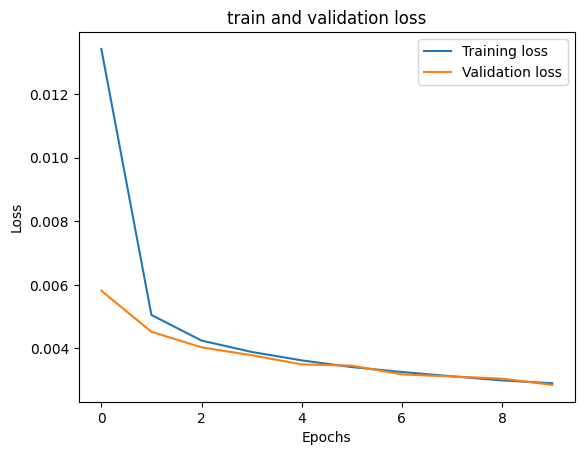

In [13]:
# 12. Evaluate Model
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

plt.plot(history.history['loss'], label="Training loss")
plt.plot(history.history['val_loss'], label="Validation loss")
plt.title("train and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()